# Deep Learning: PINNs and OOD generalization

## Context

In many engineering problems, we want to establish mathematical models in order to predict the evolution of physical processes. In general, we have accurate but few measurement data over a narrow range of parameters, as well as a physical model that is often not very accurate but valid over a wide range of parameters. The goal of this mini-project is to combine the strengths of learning models (accurate but with limited generalization) and physical models (sometimes not very accurate but robust).

In this mini-project, I will:

1. Generate synthetic data from a parameterized ODE.
2. Train an MLP using supervised learning to approximate the solution.
3. Study In-Distribution (ID) vs Out-of-Distribution (OOD) generalization.
4. Implement a **Physics-Informed Neural Network (PINN)** based on the ODE residual.
5. Train a **hybrid** model combining supervision (ID) and physical constraints (OOD).
6. Quantitatively and qualitatively compare the 3 approaches: supervised, pure PINN, hybrid.

## Problème étudié




In [1]:
# setup and imports
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

torch.manual_seed(42) # For reproducibility
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # GPU if available
device

device(type='cpu')

## Part 1 — Data generation (ID and OOD)

We consider the following parameterized ODE:

\begin{cases}
\displaystyle \frac{\partial y}{\partial t}(t, k) = -k \, y(t, k), \quad k > 0, \\
y(0, k) = 1.
\end{cases}

The analytical solution is $y(t, k) = e^{-k t}$.


- Time domain: $ t \in [0, 8] $
- **ID** domain (In-Distribution): $ k \in [0.1, 0.5] $
- **OOD** domain (Out-of-Distribution): $ k \in [0.6, 1.0] $


**Objectives:**

- Generate a set of values of $t \in [0,8]$.
- Generate an **ID** dataset:
  - Generate a set of values of $k \in $ **ID**.
  - Generate the corresponding solutions
  - Organize the data as follows:
    - Inputs: $(t, k)$ (tensor of size `[N, 2]`)
    - Outputs: $y$ (tensor of size `[N, 1]`)
  - Split the ID data into **train / validation / test**, making sure to split by **trajectory** (i.e. by value of k)
- Similarly generate an OOD test set.
- Visualize some **ID** and **OOD** data trajectories.

In [2]:
def y_exact(k: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
    """
    Analytical solution of the ODE: y(t, k) = exp(-k * t)
    
    k: tensor of size [N] or [N, 1]
    t: tensor of size [N] or [N, 1]
    Returns: tensor y of the same size
    """
    return torch.exp(-k*t)

In [3]:
def generate_data(
    k: torch.tensor,
    t_min=0.0, t_max=8.0, n_t=200
):
    """
    Generates the data:
    - len(k) values of k
    - n_t time points uniformly distributed between [t_min, t_max]
    
    Returns:
        X: tensor [N, 2] with columns (k, t)
        y: tensor [N, 1]
    """
    n_k = len(k)
    t = torch.linspace(start=t_min, end=t_max, steps=n_t).reshape([-1,1])
    X = torch.empty([n_k*n_t,2])
    
    for i in range(n_k):
        for j in range(n_t):
            X[n_t*i+j,0], X[n_t*i+j,1] = k[i], t[j]
    return (X, y_exact(X[:,0], X[:,1]).reshape([-1,1]))

Following Thibault Faney's advice, we recoded a function that performs a train/validation/test split.

In [4]:
def train_val_test_split(
    k_min=0.1, k_max=0.5, n_k=20,
    val_ratio=0.15,
    test_ratio=0.15
):
    """
    Splits the ID data into train/val/test by k values.
    The k values are uniformly distributed between [k_min, k_max].
    """
    k = np.linspace(start=k_min, stop=k_max, num=n_k)
    
    num_val = int(val_ratio*n_k)
    num_test = int(test_ratio*n_k)
    val_k = np.empty((num_val,),dtype=float)
    test_k = np.empty((num_test,),dtype=float)
    
    for i in range(num_val):
        rd = np.random.random()
        index = int(rd*len(k))
        val_k[i] = k[index]
        k = np.delete(k,index)
        
    for j in range(num_test):
        rd = np.random.random()
        index = int(rd*len(k))
        test_k[j] = k[index]
        k = np.delete(k,index)
        
    train_torch = torch.Tensor(k.reshape(-1,1))
    val_torch = torch.Tensor(val_k.reshape(-1,1))
    test_torch = torch.Tensor(test_k.reshape(-1,1))
    
    return(generate_data(train_torch), generate_data(val_torch), generate_data(test_torch))

In [5]:
(train, val, test) = train_val_test_split()

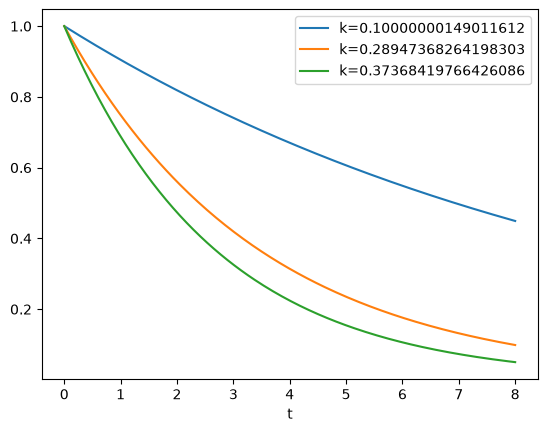

In [6]:
def plot_trajectories(X, y, n_traj=3):
    
    X = X.numpy()
    y = y.numpy()

    k_vals = np.random.choice(np.unique(X[:,0]),size=n_traj, replace=False)
    for k in k_vals:
        mask = X[:,0]==k
        plt.plot(X[mask][:,1], y[mask], label=f'k={k}')

    plt.xlabel('t')
    plt.legend()
    plt.show()

plot_trajectories(*train)

## Part 2 — Purely supervised MLP model (ID only)

We want to approximate the function $ (t, k) \mapsto y(t,k) $ using an MLP neural network.

### Objectives

1. Implement an MLP that takes $ (t, k) $ as input and outputs $ \hat{y}(t,k) $.
2. Train this MLP **only** on the ID - train data.
3. Perform a **coarse hyperparameter search** (i.e. network size, activation function type, learning rate).
4. Evaluate the model:
   - on ID - test,
   - on OOD - test
5. Visualize the predicted vs true trajectories.

### Reminders

- Supervised loss (MSE):
$ \mathcal{L}_{\text{sup}} = \frac{1}{N} \sum_{(t,k)} (\hat{y}(t,k) - y(t,k))^2 $

In [7]:
class MLP(nn.Module):
    def __init__(self, in_dim=2, out_dim=1, hidden_sizes=(64, 64), activation=nn.Tanh()):
        """
        Simple fully-connected MLP.
        
        - Sequence of linear layers + activations.
        """
        super().__init__()
        self.activation = activation

        layers = []
        layer1 = nn.Linear(in_dim, hidden_sizes[0])
        layers.append(layer1)
        layers.append(activation)
        layer2 = nn.Linear(*hidden_sizes)
        layers.append(layer2)
        layers.append(activation)
        layer3 = nn.Linear(hidden_sizes[1], out_dim)
        layers.append(layer3)
        layers.append(activation)
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)


In [8]:
def train_supervised(
    model,
    train_loader,
    val_loader,
    n_epochs=1000,
    lr=1e-3,
    verbose_every=100
):
    """
    Trains the model in supervised mode on the ID (train) data,
    and tracks performance on val.
    Returns the train_losses and val_losses lists.
    """
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    
    train_losses = []
    val_losses = []
    
    for epoch in range(1, n_epochs + 1):
        # ---- Training phase ----
        model.train()
        running_train_loss = 0.0
        
        for batch in train_loader:
            X_batch, y_batch = batch
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            # implement the model prediction, loss calculation, backpropagation, and update of the network weights
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item()
        
        train_losses.append(running_train_loss/len(train_loader))
        
        # ---- Validation phase ----
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch in val_loader:
                X_batch, y_batch = batch
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                
                y_pred = model(X_batch)
                loss = criterion(y_pred, y_batch)
                val_loss += loss.item()
        
        val_losses.append(val_loss/len(val_loader))
        
        if epoch % verbose_every == 0:
            print(f"[Epoch {epoch}/{n_epochs}] Train_loss/batch = {train_losses[-1]}  Val_loss/batch = {val_losses[-1]}")
    
    return train_losses[-1], val_losses[-1]

In [9]:
train_id_dataset = TensorDataset(train[0], train[1])
val_id_dataset = TensorDataset(val[0], val[1])

train_id_loader = DataLoader(train_id_dataset, batch_size=64, shuffle=True, drop_last=True)
val_id_loader = DataLoader(val_id_dataset, batch_size=64, shuffle=True, drop_last=True)

In [10]:
# Define a simple search space over a few hyperparameters
hidden_sizes = [(32, 32), (64, 64), (128, 128)]
lrs = [1e-3, 5e-4]
activations = [nn.ReLU(), nn.SiLU(), nn.Tanh()]

def search_space(hidden_sizes, lrs, activations):
	search_space = []
	for i in range(len(hidden_sizes)):
		for j in range(len(lrs)):
			for k in range(len(activations)):
				search_space.append({'hidden_sizes': hidden_sizes[i], 'lr': lrs[j], 'activation': activations[k]})
	return search_space

search_space_ = search_space(hidden_sizes, lrs, activations)

results_supervised = []

best_cfg = search_space_[0]
best_loss = np.inf

for cfg in search_space_:
	print("Config:", cfg)
	model = MLP(in_dim=2, out_dim=1, hidden_sizes=cfg['hidden_sizes'],activation=cfg['activation'])
	train_loss_cfg, val_loss_cfg = train_supervised(model, train_id_loader, val_id_loader, n_epochs=200, lr=cfg['lr'])
	if val_loss_cfg < best_loss:
		best_loss = val_loss_cfg
		best_cfg = cfg

print('\n', f'Best config for pure MLP: {best_cfg}')

Config: {'hidden_sizes': (32, 32), 'lr': 0.001, 'activation': ReLU()}
[Epoch 100/200] Train_loss/batch = 3.891437915817098e-05  Val_loss/batch = 4.836794485325097e-05
[Epoch 200/200] Train_loss/batch = 2.70055333689819e-05  Val_loss/batch = 2.5621134126494224e-05
Config: {'hidden_sizes': (32, 32), 'lr': 0.001, 'activation': SiLU()}
[Epoch 100/200] Train_loss/batch = 0.00027990204127786985  Val_loss/batch = 0.0003699091062622352
[Epoch 200/200] Train_loss/batch = 1.2985135442228734e-05  Val_loss/batch = 1.1777520942107205e-05
Config: {'hidden_sizes': (32, 32), 'lr': 0.001, 'activation': Tanh()}
[Epoch 100/200] Train_loss/batch = 0.00018610670227898544  Val_loss/batch = 0.00015646304867307967
[Epoch 200/200] Train_loss/batch = 1.8303219010619594e-05  Val_loss/batch = 1.6785237322538807e-05
Config: {'hidden_sizes': (32, 32), 'lr': 0.0005, 'activation': ReLU()}
[Epoch 100/200] Train_loss/batch = 9.36200829232274e-05  Val_loss/batch = 0.00010206644017469241
[Epoch 200/200] Train_loss/batch 

We observe that the best-performing model is the one with 128 _hidden sizes_ and SiLU as the activation function. 
We will keep these parameters for the remaining parts.

In [11]:
def evaluate_model(model, data_loader):
    """
    Returns the average MSE on the data from data_loader.
    """
    model.eval()
    model.to(device)
    criterion = nn.MSELoss(reduction="mean")
    total_loss = 0.0
    n_batches = 0
    with torch.no_grad():
        for (X_batch, y_batch) in data_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            y_hat = model(X_batch)
            loss = criterion(y_hat, y_batch)
            total_loss += loss.item()
            n_batches += 1
    return total_loss / max(1, n_batches)


model_sup = MLP(in_dim=2, out_dim=1, hidden_sizes=best_cfg['hidden_sizes'],activation=best_cfg['activation'])
train_loss_cfg, val_loss_cfg = train_supervised(model_sup, train_id_loader, val_id_loader, n_epochs=200, lr=best_cfg['lr'])

test_id_dataset = TensorDataset(train[0], train[1])
test_id_loader = DataLoader(test_id_dataset, batch_size=64, shuffle=True, drop_last=True)
mse_id = evaluate_model(model_sup, test_id_loader)

(test_ood_X, test_ood_y) = generate_data(k=torch.linspace(0.6,1.0,20))
test_ood_dataset = TensorDataset(test_ood_X, test_ood_y)
test_ood_loader = DataLoader(test_ood_dataset, batch_size=64, shuffle=True, drop_last=True)
mse_ood = evaluate_model(model_sup, test_ood_loader)

print("\n", "Supervised MLP - MSE ID:", mse_id)
print("Supervised MLP - MSE OOD:", mse_ood)
print("\n", "Supervised MLP - MSE OOD/MSE ID:", mse_ood/mse_id)

[Epoch 100/200] Train_loss/batch = 4.589738518704909e-05  Val_loss/batch = 7.431233502251821e-05
[Epoch 200/200] Train_loss/batch = 2.9140922572159346e-05  Val_loss/batch = 8.740858397181404e-06

 Supervised MLP - MSE ID: 1.0222887562291403e-05
Supervised MLP - MSE OOD: 0.0003161866209871556

 Supervised MLP - MSE OOD/MSE ID: 30.92928676565471


We observe that the pure (supervised) MLP model performs much better on data included in its training domain.

When the model is asked to extrapolate predictions to parameters outside the training domain, accuracy drops drastically. The MSE is about 30 to 50 times higher. __We observe that a pure MLP is very limited when it comes to extrapolation.__

In [12]:
# - For a few values of k (ID and OOD), plot:
#   - y_exact(t,k) curve
#   - y_hat(t,k) curve predicted by the supervised model
def plot_model_vs_exact(model, X, title):
    """
    For a few values of k (ID and OOD), plot:
    - y_exact(t,k) curve;
    - y_hat(t,k) curve predicted by the supervised model.
    """
    
    X = X.numpy()

    colors = ['blue','red','green']
    plt.figure(figsize=(12, 7))

    for i, k in enumerate(np.random.choice(np.unique(X[:,0]), size=3, replace=False)):

        X_k = X[X[:,0]==k]
        X_k_tensor = torch.Tensor(X_k)
        y_hat = model(X_k_tensor)

        plt.plot(X_k[:,1], y_exact(X_k_tensor[:,0], X_k_tensor[:,1]), label=f'Exact k={k}', color=colors[i], linestyle='-')
        plt.plot(X_k[:,1], y_hat.detach().numpy(), label=f'Pred k={k}', color=colors[i], linestyle='--')
    
    plt.xlabel('t')
    plt.ylabel('y(t,k)')
    plt.title(title)
    plt.legend()
    plt.show()

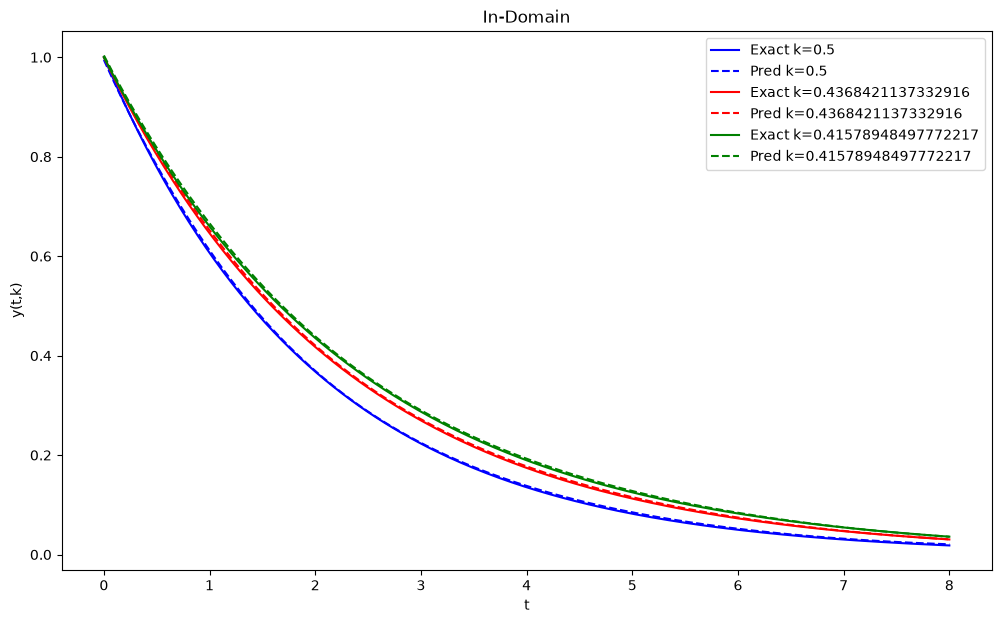

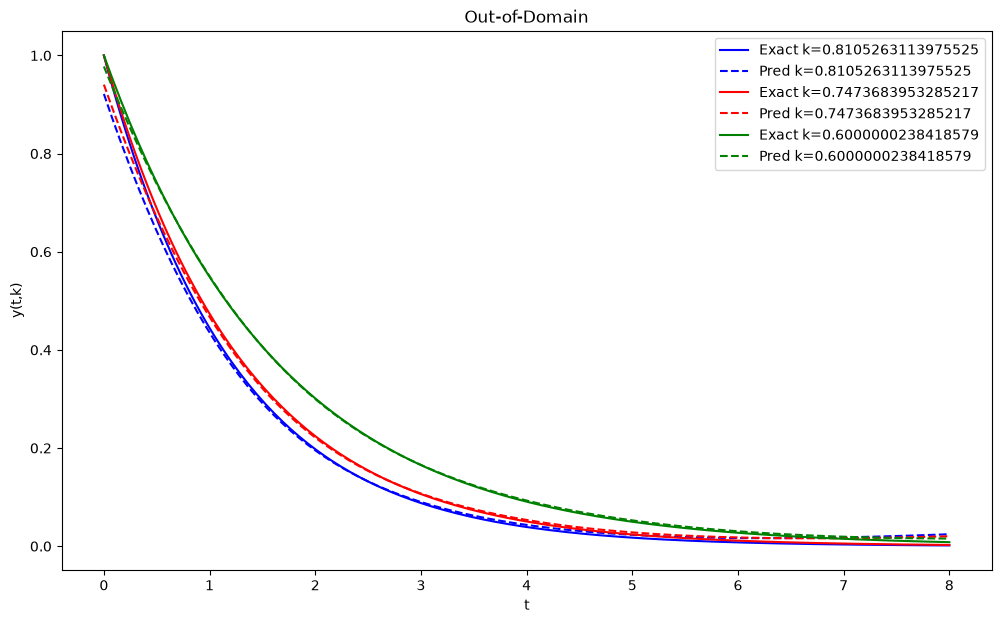

In [13]:
X_plot_id, y_plot_id = generate_data(k=np.linspace(0.1,0.5,20))
X_plot_ood, y_plot_ood = generate_data(k=np.linspace(0.6,1.,20))
plot_model_vs_exact(model_sup, X_plot_id, title='In-Domain')
plot_model_vs_exact(model_sup, X_plot_ood, title='Out-of-Domain')

We can refine the previous MSE analysis: the model's predictions outside the training domain deteriorate particularly at the boundary conditions (near t = 0 and as t tends to infinity).

It seems worthwhile to inform the model with known physical boundary conditions, to force it to respect the ODE constraints even outside the training domain.

In [14]:
# 3D representation
from matplotlib import cm

def plot_3D(model, X, title):

	X2 = X.numpy()

	fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

	k = np.unique(X2[:,0])
	t = np.unique(X2[:,1])
	nk, nt = k.shape[0], t.shape[0]
	t, k = np.meshgrid(t, k)

	z = model(X).detach().numpy()
	z = z.reshape((nk,nt))

	surf = ax.plot_surface(t, k, z, cmap=cm.coolwarm, linewidth=0, antialiased=False)
	ax.set_xlabel('t')
	ax.set_ylabel('k')
	ax.set_title(title)

	# Color bar
	fig.colorbar(surf, shrink=0.5, aspect=5)

	plt.show()

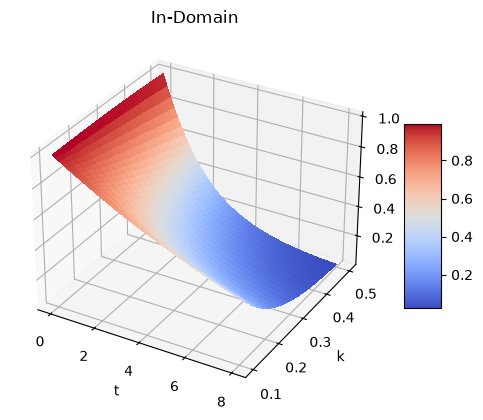

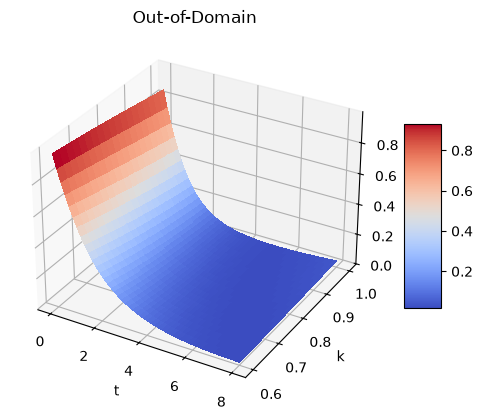

In [15]:
plot_3D(model_sup, X_plot_id, 'In-Domain')
plot_3D(model_sup, X_plot_ood, 'Out-of-Domain')

## Part 3 — Pure PINN on the OOD domain

We now train a model **without labels $ y $** on the OOD domain, using only:

- the ODE residual,
- the initial conditions $ y(0,k)=1 $.

We use the same type of network (MLP).

### ODE residual

For an approximation $ \hat{y}(t,k) $, we define:

$ r(t,k) = \frac{\partial \hat{y}}{\partial t}(t,k) + k \hat{y}(t,k) $.

The derivative $ \frac{\partial \hat{y}}{\partial t} $ will be obtained via **automatic differentiation**.

### PINN loss

- Residual loss:  
$ \mathcal{L}_{\text{res}} = \frac{1}{N_{\text{colloc}}} \sum r(t,k)^2 $

- Initial condition loss (IC):  
$ \mathcal{L}_{\text{IC}} = \frac{1}{N_{\text{IC}}} \sum (\hat{y}(0,k) - 1)^2 $

- Total loss:
$ \mathcal{L}_{\text{PINN}} = \mathcal{L}_{\text{res}} + \lambda_{\text{IC}} \mathcal{L}_{\text{IC}} $

We can also explore the parameterization $\hat{y}(t,k) = 1 + t N_\theta(t,k)$, which avoids the need for $ \mathcal{L}_{\text{IC}} $.

Objectives:

1. Implement the residual calculation using autograd.
2. Implement the PINN loss.
3. Train the model only on collocation points (OOD - train) + initial conditions.
4. Evaluate the model on OOD - test and ID - test.

In [16]:
def sample_ic_points_ood(
    n_points=1000,
    k_min=0.6, k_max=1.0):
    """
    Points for the initial condition: t=0, k ∈ [k_min, k_max].
    """
    k = np.linspace(k_min, k_max, 10000)
    ic = np.random.choice(k, size=n_points, replace=False)

    return generate_data(k = torch.Tensor(ic), t_min=0,t_max=0,n_t= 1)[0]

In [17]:
def pinn_residual(model, k, t):    
    k = k.clone().detach().to(device)
    t = t.clone().detach().to(device).requires_grad_(True)
    
    # Build the input (t, k)
    X = torch.cat([k, t], dim=1)  # [N, 2]
    y_hat = model(X)
    
    try:
        # 3. Calculate the dy/dt gradient via Autograd
        dy_dt = torch.autograd.grad(
            outputs=y_hat,
            inputs=t,
            grad_outputs=torch.ones_like(y_hat), 
            create_graph=True,                   
            retain_graph=True
        )[0]
        r = dy_dt + k * y_hat
        return r
    
    except RuntimeError:
        return torch.tensor([0.])

In [18]:
def train_pinn_ood(
    model,
    train_loader_colloc,
    val_loader_colloc=None,
    n_ic=1000,
    n_epochs=1000,
    lr=1e-3,
    lambda_ic=1.0,
    verbose_every=100
):
    """
    Trains a PINN on the OOD domain only, using collocation points
    provided by a DataLoader (train_loader_colloc, val_loader_colloc).

    Each batch of train_loader_colloc must contain X_colloc of size [batch_size, 2]
    with columns (k, t). If your dataset also contains labels y, they will be ignored.

    train_loader_colloc : DataLoader of OOD points (k,t) used as collocation (train)
    val_loader_colloc   : DataLoader of OOD points (k,t) used as collocation (val, optional)
    """
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    for epoch in range(1, n_epochs + 1):
        model.train()
        running_L_res = 0.0
        running_L_ic = 0.0
        running_L_tot = 0.0
        n_batches = 0

        # --- Loop over collocation batches (OOD train) ---
        for batch in train_loader_colloc:
            # The DataLoader may return either (X,) or (X, y) -> handle both cases
            if isinstance(batch, (list, tuple)) and len(batch) >= 1:
                X_colloc = batch[0]
            else:
                X_colloc = batch

            X_colloc = X_colloc.to(device)

            # X_colloc contains the columns (t, k)
            k_colloc = X_colloc[:, 0:1]  # shape [B, 1]
            t_colloc = X_colloc[:, 1:2]  # shape [B, 1]

            optimizer.zero_grad()

            r = pinn_residual(model, k=k_colloc, t=t_colloc)
           
            L_res = torch.mean(r**2)
            
            # --- Initial condition loss ---
            # Sample OOD points (t=0, k) to enforce y(0,k)=1
            X_ic = sample_ic_points_ood(n_ic).to(device) # [n_ic, 2]
            y_hat_ic = model(X_ic)                  # [n_ic, 1]
            target_ic = torch.ones_like(y_hat_ic)   # [n_ic, 1]
            
            L_ic = criterion(y_hat_ic, target_ic)
            
            L_tot = L_res + lambda_ic * L_ic
            L_tot.backward()
            optimizer.step()

            running_L_res += L_res.item()
            running_L_ic  += L_ic.item()
            running_L_tot += L_tot.item()
            n_batches += 1

        # after the loop, calculate the average losses for the epoch
        mean_L_res = running_L_res / max(1, n_batches)
        mean_L_ic  = running_L_ic  / max(1, n_batches)
        mean_L_tot = running_L_tot / max(1, n_batches)
        train_losses.append(mean_L_tot)


        # --- Validation on val_loader_colloc ---
        if val_loader_colloc is not None:
            model.eval()
            with torch.no_grad():
                val_L_res = 0.0
                val_batches = 0
                for batch in val_loader_colloc:
                    if isinstance(batch, (list, tuple)) and len(batch) >= 1:
                        X_val = batch[0]
                    else:
                        X_val = batch

                    X_val = X_val.to(device)
                    k_val = X_val[:, 0:1]
                    t_val = X_val[:, 1:2]

                    r_val = pinn_residual(model, k=k_val, t=t_val)
                    L_res_val = torch.mean(r_val**2)
                    val_L_res += L_res_val.item()
                    val_batches += 1

                mean_val_L_res = val_L_res / max(1, val_batches)
                val_losses.append(mean_val_L_res)
        else:
            # If there is no validation, we can add None or do nothing
            pass

        if epoch % verbose_every == 0:
            # complete the display with the actual values
            print(f"[PINN OOD] Epoch {epoch}/{n_epochs} - "
                  f"L_res(train) = {mean_L_res} - L_ic(train) ={mean_L_ic} - L_tot(train) ={mean_L_tot}")

    return train_losses[-1], val_losses[-1]

In [19]:
(train_ood, val_ood, test_ood) = train_val_test_split(k_min=0.6, k_max=1.0, n_k=20)

train_ood_X, val_ood_X, test_ood_X, test_ood_y = train_ood[0], val_ood[0], test_ood[0], test_ood[1]
train_ood_loader = DataLoader(TensorDataset(train_ood_X), batch_size=64, shuffle=True, drop_last=True)
val_ood_loader = DataLoader(TensorDataset(val_ood_X), batch_size=64, shuffle=True, drop_last=True)
test_ood_loader = DataLoader(TensorDataset(test_ood_X, test_ood_y), batch_size=64, shuffle=True, drop_last=True)

In [20]:
model_pinn = MLP(in_dim=2,out_dim=1, hidden_sizes=(128,128), activation=nn.SiLU())
train_pinn_ood(model_pinn, train_loader_colloc=train_ood_loader, val_loader_colloc=val_ood_loader, lr=0.001)

[PINN OOD] Epoch 100/1000 - L_res(train) = 5.701778750229751e-06 - L_ic(train) =9.973840770543955e-07 - L_tot(train) =6.69916281092514e-06
[PINN OOD] Epoch 200/1000 - L_res(train) = 2.7963718012383755e-06 - L_ic(train) =1.5346371252847646e-06 - L_tot(train) =4.331008915679102e-06
[PINN OOD] Epoch 300/1000 - L_res(train) = 1.3239455230114102e-06 - L_ic(train) =5.853046020402067e-06 - L_tot(train) =7.176991414854815e-06
[PINN OOD] Epoch 400/1000 - L_res(train) = 9.144024191268833e-07 - L_ic(train) =4.309189648417915e-07 - L_tot(train) =1.3453213783091193e-06
[PINN OOD] Epoch 500/1000 - L_res(train) = 3.272899465863448e-07 - L_ic(train) =7.184970617435135e-08 - L_tot(train) =3.991396550740911e-07
[PINN OOD] Epoch 600/1000 - L_res(train) = 1.240377833395605e-06 - L_ic(train) =6.144659059193441e-07 - L_tot(train) =1.8548437350186442e-06
[PINN OOD] Epoch 700/1000 - L_res(train) = 9.004391462530145e-07 - L_ic(train) =6.922503964992122e-07 - L_tot(train) =1.5926895624160838e-06
[PINN OOD] Epoc

(2.056341246408026e-06, 0.0)

In [21]:
mse_pinn_id = evaluate_model(model_pinn, test_id_loader)
mse_pinn_ood = evaluate_model(model_pinn, test_ood_loader)
mse_mlp_ood = evaluate_model(model_sup, test_ood_loader)

print(f'PINN ID error: {mse_pinn_id}')
print(f'PINN OOD error: {mse_pinn_ood}', '\n')
print(f'For reference, the MLP OOD error was: {mse_mlp_ood}')

PINN ID error: 0.012466212572140057
PINN OOD error: 7.174094056002407e-06 

For reference, the MLP OOD error was: 0.00025516541629460536


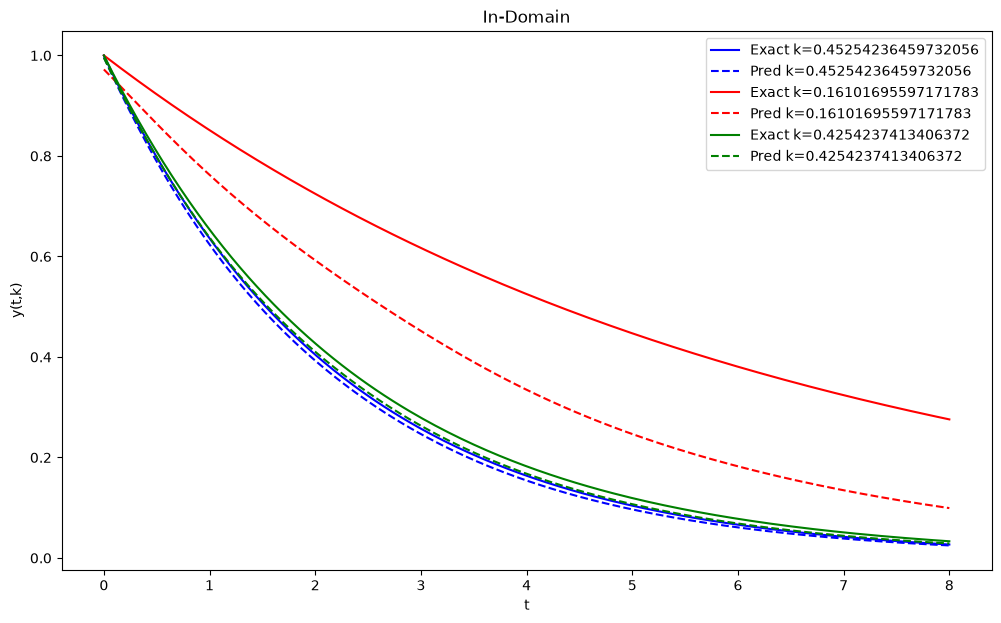

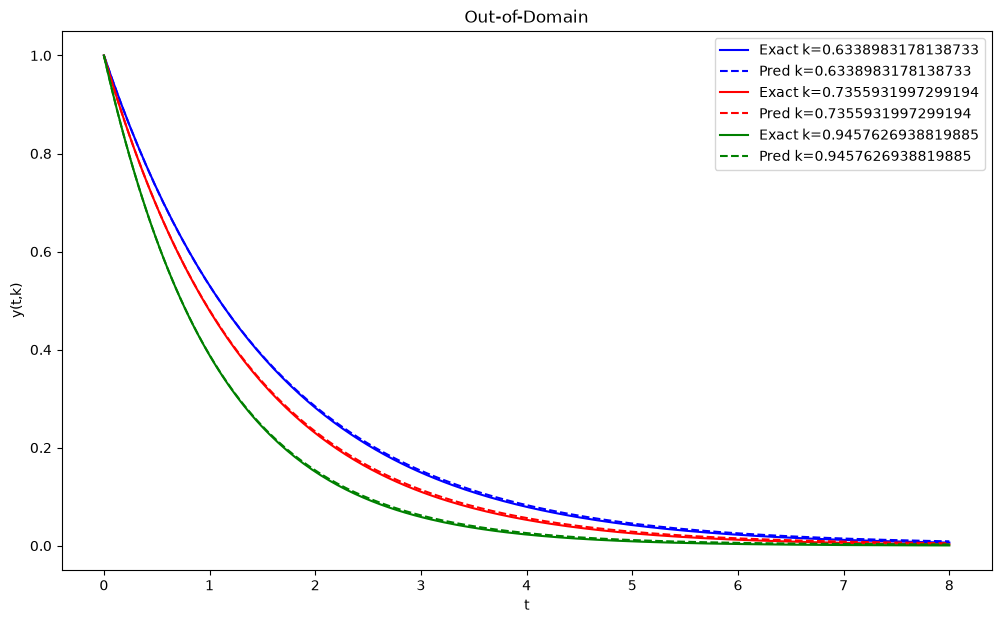

In [22]:
X_plot_id, y_plot_id = generate_data(k=np.linspace(0.1,0.5,60))
X_plot_ood, y_plot_ood = generate_data(k=np.linspace(0.6,1.,60))
plot_model_vs_exact(model_pinn, X_plot_id, title='In-Domain')
plot_model_vs_exact(model_pinn, X_plot_ood, title='Out-of-Domain')

The results show that the PINN can predict accurately in the domain where it was trained (OOD), but it also cannot extrapolate. The pure PINN model does not solve the problem observed in part 2.

It may therefore be useful to combine the two models into a hybrid model to achieve good performance across the entire ID + OOD domain.

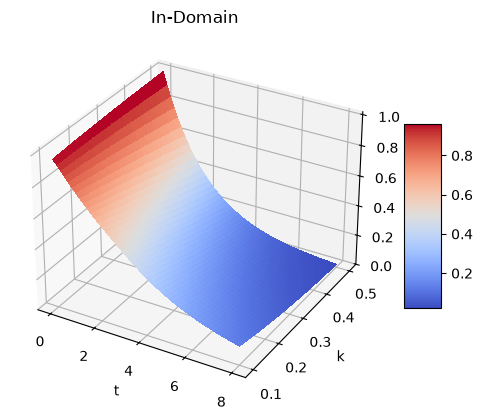

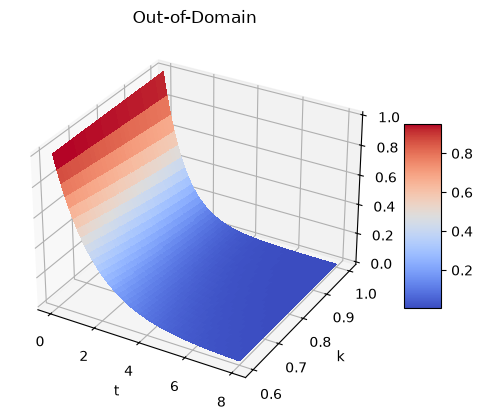

In [23]:
plot_3D(model_pinn, X_plot_id, 'In-Domain')
plot_3D(model_pinn, X_plot_ood, 'Out-of-Domain')

## Part 4 — Hybrid model: ID supervision + OOD residual

We now combine:

- a **supervised loss** on ID data,
- a **residual loss** on OOD collocation points,
- an **initial condition loss** on points generated at t = 0.

Total loss:

$ \mathcal{L}_{\text{tot}} =
\lambda_{\text{sup}} \mathcal{L}_{\text{sup, ID}} +
\lambda_{\text{res}} \mathcal{L}_{\text{res, OOD}} +
\lambda_{\text{IC}} \mathcal{L}_{\text{IC}}. $

Objectives:

1. Reuse the MLP architecture.
2. Define a hybrid training loop:
   - at each iteration:
     - a batch of **ID** data (supervised),
     - a batch of **OOD** collocation points.
3. Optionally adjust the weights $ \lambda_{\text{sup}}, \lambda_{\text{res}}, \lambda_{\text{IC}} $.
4. Evaluate the hybrid model on:
   - ID test,
   - OOD test.
5. Compare the 3 models: **supervised**, **PINN**, **hybrid**.

In [24]:
def train_hybrid(
    model,
    train_loader_id,
    train_loader_colloc,
    val_loader_id=None,
    val_loader_colloc=None,
    n_ic=1000,
    n_epochs=1000,
    lr=1e-3,
    lambda_sup=1.0,
    lambda_res=1.0,
    lambda_ic=1.0,
    verbose_every=500
):
    """
    Trains a hybrid model:
    - supervision on ID data (train_loader_id)
    - PINN residual on OOD collocation points (train_loader_colloc)
    - BC on OOD (t=0)

    Each batch of train_loader_colloc must contain X_colloc of shape [batch_size, 2]
    with columns (k, t). If your dataset also contains labels, they will be ignored.
    """
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    for epoch in range(1, n_epochs + 1):
        model.train()

        running_L_sup = 0.0
        running_L_res = 0.0
        running_L_ic  = 0.0
        running_L_tot = 0.0
        n_batches = 0

        # Iterator over OOD collocation batches
        colloc_iter = iter(train_loader_colloc)

        # --- Loop over supervised ID batches ---
        for X_sup, y_sup in train_loader_id:
            X_sup = X_sup.to(device)
            y_sup = y_sup.to(device)

            # Get a batch of OOD collocation points (t,k)
            try:
                batch_colloc = next(colloc_iter)
            except StopIteration:
                # If we have exhausted the OOD DataLoader, start again from the beginning
                colloc_iter = iter(train_loader_colloc)
                batch_colloc = next(colloc_iter)

            if isinstance(batch_colloc, (list, tuple)) and len(batch_colloc) >= 1:
                X_colloc = batch_colloc[0]
            else:
                X_colloc = batch_colloc

            X_colloc = X_colloc.to(device)
            k_colloc = X_colloc[:, 0:1]  # [B,1]
            t_colloc = X_colloc[:, 1:2]  # [B,1]

            optimizer.zero_grad()

            # --- ID supervised loss ---
            y_hat_sup = model(X_sup)
            L_sup = criterion(y_hat_sup, y_sup)

            # --- OOD residual loss ---
            r = pinn_residual(model, k= k_colloc, t=t_colloc)
            L_res = torch.mean(r**2)

            # --- OOD BC loss (t=0) ---
            # Sample OOD points (t=0, k) to enforce y(0,k)=1
            X_ic = sample_ic_points_ood(n_ic).to(device) # [n_ic, 2]
            y_hat_ic = model(X_ic)                  # [n_ic, 1]
            target_ic = torch.ones_like(y_hat_ic)   # [n_ic, 1]
            L_ic = criterion(y_hat_ic, target_ic)

            # --- Total loss ---
            L_tot = lambda_sup * L_sup + lambda_res * L_res + lambda_ic * L_ic

            # backward + step
            L_tot.backward()
            optimizer.step()

            running_L_sup += L_sup.item()
            running_L_res += L_res.item()
            running_L_ic  += L_ic.item()
            running_L_tot += L_tot.item()
            n_batches += 1

        # average losses for the epoch
        mean_L_sup = running_L_sup / max(1, n_batches)
        mean_L_res = running_L_res / max(1, n_batches)
        mean_L_ic  = running_L_ic  / max(1, n_batches)
        mean_L_tot = running_L_tot / max(1, n_batches)
        train_losses.append(mean_L_tot)

        # --- Optional validation ---
        if (val_loader_id is not None) and (val_loader_colloc is not None):
            model.eval()
            with torch.no_grad():
                val_L_tot = 0.0
                val_batches = 0

                colloc_iter_val = iter(val_loader_colloc)

                for X_sup_val, y_sup_val in val_loader_id:
                    X_sup_val = X_sup_val.to(device)
                    y_sup_val = y_sup_val.to(device)

                    try:
                        batch_colloc_val = next(colloc_iter_val)
                    except StopIteration:
                        colloc_iter_val = iter(val_loader_colloc)
                        batch_colloc_val = next(colloc_iter_val)

                    if isinstance(batch_colloc_val, (list, tuple)) and len(batch_colloc_val) >= 1:
                        X_colloc_val = batch_colloc_val[0]
                    else:
                        X_colloc_val = batch_colloc_val

                    X_colloc_val = X_colloc_val.to(device)
                    k_colloc_val = X_colloc_val[:, 0:1]
                    t_colloc_val = X_colloc_val[:, 1:2]

                    # reproduce the calculation of L_sup, L_res, L_ic for validation
                    # (without backward)
                    
                    y_hat_sup_val = model(X_sup_val)
                    L_sup_val = criterion(y_hat_sup_val, y_sup_val)
                    
                    r_val = pinn_residual(model, t_colloc_val, k_colloc_val)
                    L_res_val = torch.mean(r_val**2)
                    
                    X_ic = sample_ic_points_ood(n_ic).to(device) # [n_ic, 2]
                    y_hat_ic = model(X_ic)                  # [n_ic, 1]
                    target_ic = torch.ones_like(y_hat_ic)   # [n_ic, 1]
                    L_ic_val = criterion(y_hat_ic, target_ic)
                    
                    L_tot_val = lambda_sup * L_sup_val + lambda_res * L_res_val + lambda_ic * L_ic_val
                    
                    val_L_tot += L_tot_val.item()
                    val_batches += 1

                mean_val_L_tot = val_L_tot / max(1, val_batches)
                val_losses.append(mean_val_L_tot)

        if epoch % verbose_every == 0:

            print(f"[Hybride] Epoch {epoch}/{n_epochs} - "
                  f"L_sup(train) = {mean_L_sup} - L_res(train) = {mean_L_res} - L_ic(train) = {mean_L_ic} - L_tot(train) = {mean_L_tot}")

    return train_losses[-1], val_losses[-1]

In [25]:
model_hybrid = MLP(in_dim=2,out_dim=1, hidden_sizes=(128,128), activation=nn.SiLU())
train_hybrid(model_hybrid, 
             train_loader_id=train_id_loader,
             train_loader_colloc=train_ood_loader,
             val_loader_id=val_id_loader, 
             val_loader_colloc=val_ood_loader)

mse_hybrid_id = evaluate_model(model_hybrid, test_id_loader)
mse_hybrid_ood = evaluate_model(model_hybrid, test_ood_loader)

print('\n', f'HYBRID ID error: {mse_hybrid_id}')
print(f'HYBRID OOD error: {mse_hybrid_ood}')
print(f'HYBRID ID error/OOD error: {mse_hybrid_id/mse_hybrid_ood}')

[Hybride] Epoch 500/1000 - L_sup(train) = 1.4472509810518607e-06 - L_res(train) = 3.8572556613369373e-07 - L_ic(train) = 1.418617834892866e-06 - L_tot(train) = 3.2515943617845762e-06
[Hybride] Epoch 1000/1000 - L_sup(train) = 1.662040155116132e-06 - L_res(train) = 4.777134963369674e-07 - L_ic(train) = 4.19389173229383e-07 - L_tot(train) = 2.559142842528672e-06

 HYBRID ID error: 3.5080058804068845e-07
HYBRID OOD error: 1.1711653908403403e-07
HYBRID ID error/OOD error: 2.9953121120577197


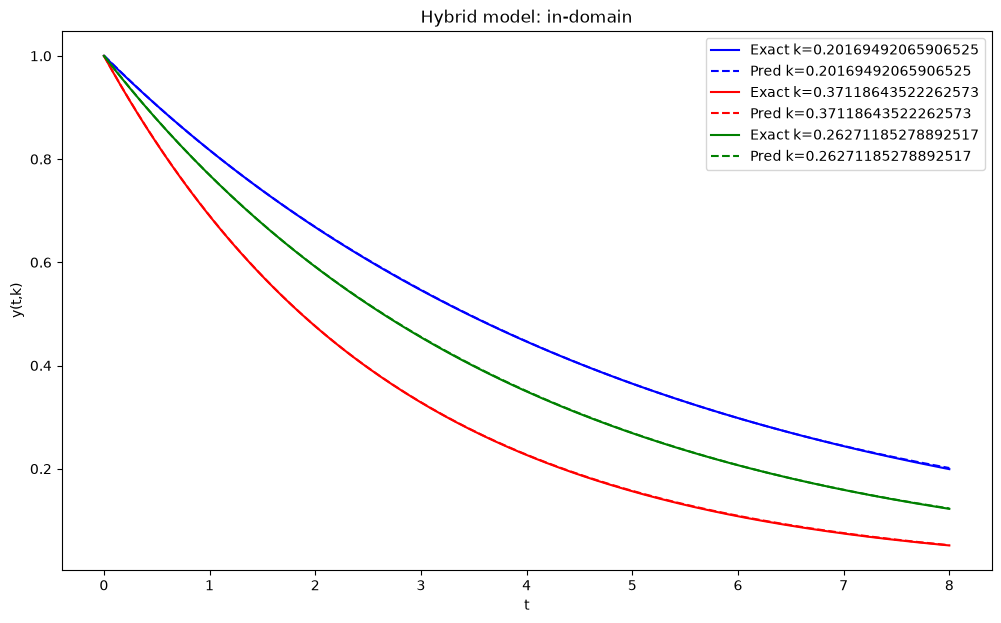

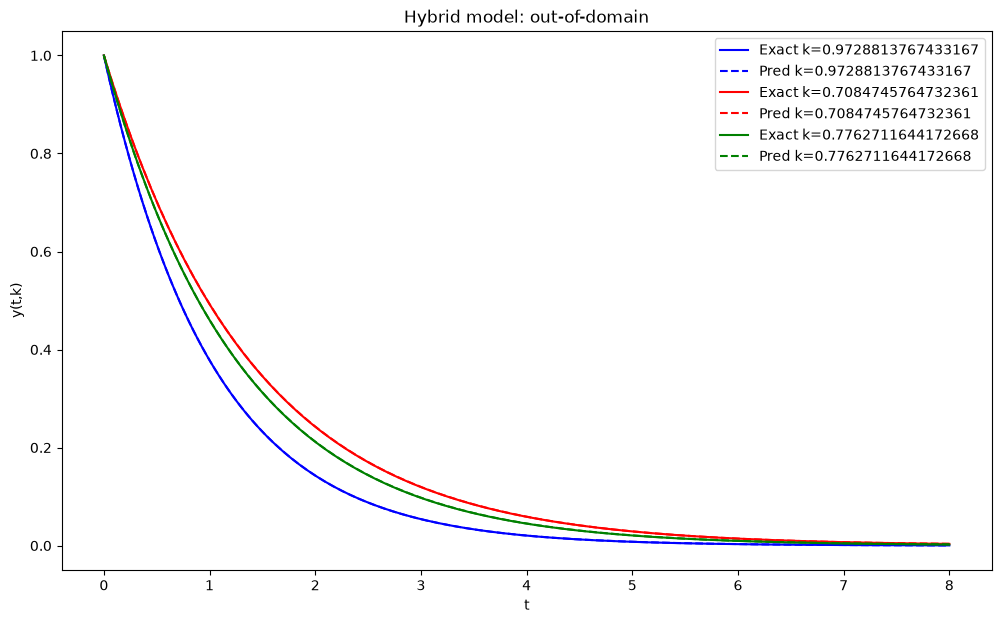

In [26]:
plot_model_vs_exact(model_hybrid, X_plot_id, 'Hybrid model: in-domain')
plot_model_vs_exact(model_hybrid, X_plot_ood, 'Hybrid model: out-of-domain')

The results show that the hybrid architecture performs better than the classic PINN on ID data, while maintaining excellent performance on OOD data. This good generalization comes from the complementary nature of the methods: supervision constrains the model in the known domain, while the PDE residual term ensures compliance with physical laws in unknown regions. Performance is of the same order of magnitude on both the ID and OOD domains.

The hybrid approach is suitable for applications with a large shift between training data and the actual application domain. The hybrid model allows extrapolation to new domains or transfer of the model to new conditions.

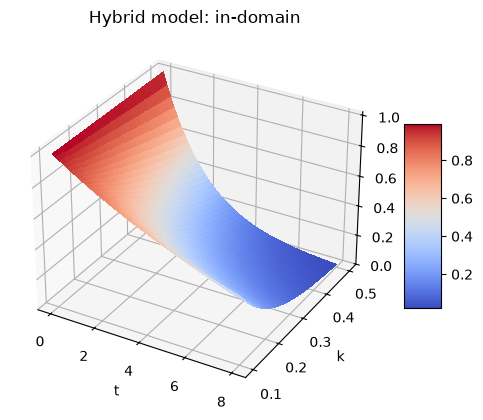

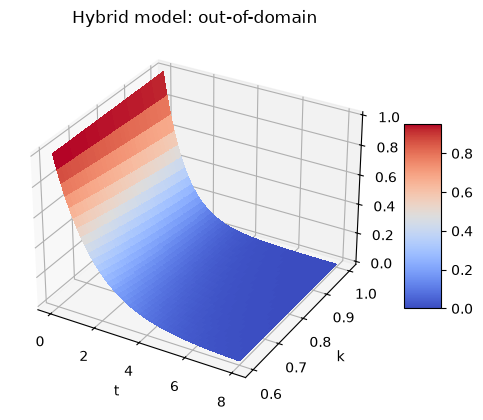

In [27]:
plot_3D(model_hybrid, X_plot_id, 'Hybrid model: in-domain')
plot_3D(model_hybrid, X_plot_ood, 'Hybrid model: out-of-domain')